<a href="https://colab.research.google.com/github/naylaakas/PembelajaranMesin-2026/blob/main/JS05/Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:

# Instalasi pustaka hdbscan
!pip install hdbscan

# Import modul
import matplotlib.pyplot as plt
import numpy as np

from sklearn.cluster import DBSCAN
from sklearn.datasets import load_iris
import hdbscan

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    adjusted_rand_score
)

In [9]:
# Memuat dataset Iris
iris = load_iris()

X = iris.data
labels_true = iris.target

print("Jumlah data:", X.shape[0])
print("Jumlah fitur:", X.shape[1])
print("Nama fitur:", iris.feature_names)
print("Label asli:", iris.target_names)


Jumlah data: 150
Jumlah fitur: 4
Nama fitur: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Label asli: ['setosa' 'versicolor' 'virginica']


In [10]:
# Normalisasi

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [4]:
# Clustering menggunakan HDBSCAN

hdb = hdbscan.HDBSCAN(
    min_cluster_size=5,
    min_samples=5
)

labels_pred = hdb.fit_predict(X_scaled)

# Menghitung jumlah cluster dan noise
n_clusters = len(set(labels_pred)) - (1 if -1 in labels_pred else 0)
n_noise = np.sum(labels_pred == -1)

print("Jumlah cluster:", n_clusters)
print("Jumlah noise:", n_noise)
print("Persentase noise:", round(n_noise / len(X_scaled) * 100, 2), "%")


Jumlah cluster: 2
Jumlah noise: 2
Persentase noise: 1.33 %


In [11]:
def plot(X, labels, probabilities=None, parameters=None,
         ground_truth=False, ax=None):

    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))

    labels = np.asarray(labels)

    if probabilities is None:
        probabilities = np.ones(X.shape[0])

    unique_labels = sorted(set(labels))
    colors = [
        plt.cm.Spectral(each)
        for each in np.linspace(0, 1, len(unique_labels))
    ]

    proba_map = {
        idx: probabilities[idx]
        for idx in range(len(labels))
    }

    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]  # Hitam untuk noise

        class_index = np.where(labels == k)[0]

        for ci in class_index:
            ax.plot(
                X[ci, 0],
                X[ci, 1],
                "x" if k == -1 else "o",
                markerfacecolor=tuple(col),
                markeredgecolor="k",
                markersize=(
                    4 if k == -1
                    else 1 + 5 * proba_map[ci]
                )
            )

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    preamble = "True" if ground_truth else "Estimated"

    title = f"{preamble} number of clusters: {n_clusters}"

    if parameters is not None:
        parameters_str = ", ".join(
            f"{k}={v}" for k, v in parameters.items()
        )
        title += f" | {parameters_str}"

    ax.set_title(title)
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")


In [12]:
# Clustering menggunakan HDBSCAN
hdb = hdbscan.HDBSCAN(
    min_cluster_size=5,
    min_samples=5
)

labels_pred = hdb.fit_predict(X_scaled)

# Menghitung jumlah cluster
n_clusters = len(set(labels_pred)) - (
    1 if -1 in labels_pred else 0
)

# Menghitung jumlah noise
n_noise = np.sum(labels_pred == -1)

print("Jumlah cluster:", n_clusters)
print("Jumlah noise:", n_noise)
print(
    "Persentase noise:",
    round(n_noise / len(X_scaled) * 100, 2),
    "%"
)


Jumlah cluster: 2
Jumlah noise: 2
Persentase noise: 1.33 %


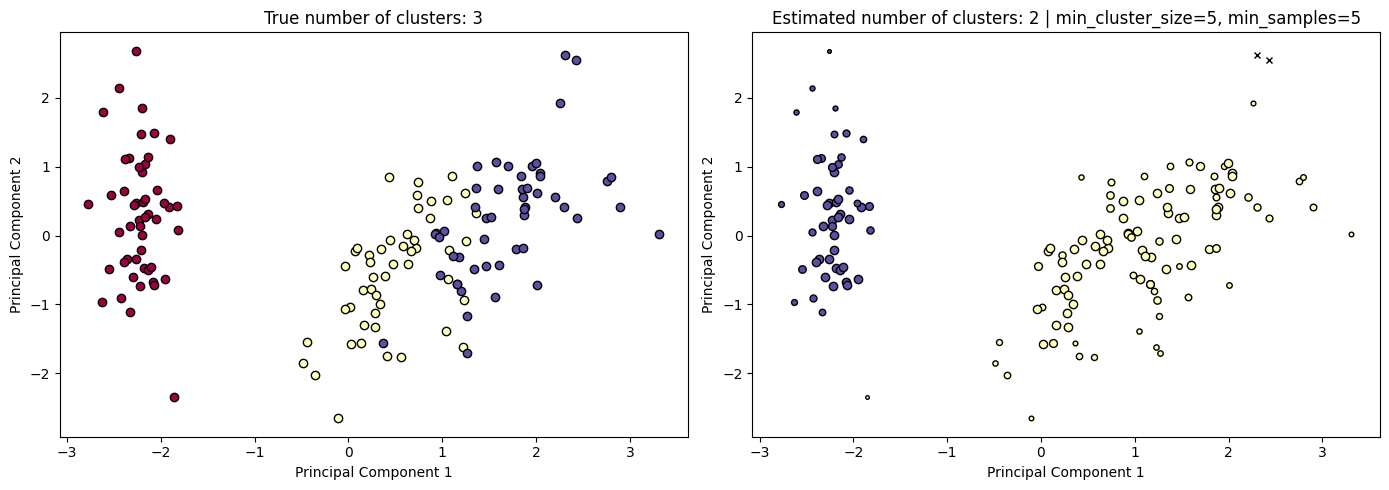

In [13]:
# Reduksi dimensi menggunakan PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Membuat dua grafik
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Grafik label asli
plot(
    X_pca,
    labels_true,
    ground_truth=True,
    ax=axes[0]
)

# Grafik hasil clustering HDBSCAN
plot(
    X_pca,
    labels_pred,
    probabilities=hdb.probabilities_,
    parameters={
        "min_cluster_size": 5,
        "min_samples": 5
    },
    ax=axes[1]
)

plt.tight_layout()
plt.show()


In [14]:
# Membandingkan hasil clustering dengan label asli
ari_score = adjusted_rand_score(labels_true, labels_pred)
print("Adjusted Rand Index:", round(ari_score, 4))

# Mengeluarkan noise untuk evaluasi internal
mask = labels_pred != -1
X_clean = X_scaled[mask]
labels_clean = labels_pred[mask]

# Silhouette Score dan Davies-Bouldin Index
n_labels = len(np.unique(labels_clean))

if 2 <= n_labels < len(X_clean):
    sil_score = silhouette_score(X_clean, labels_clean)
    dbi_score = davies_bouldin_score(X_clean, labels_clean)

    print("Silhouette Score:", round(sil_score, 4))
    print("Davies-Bouldin Index:", round(dbi_score, 4))
else:
    print(
        "Silhouette Score dan Davies-Bouldin Index "
        "tidak dapat dihitung dengan jumlah cluster ini."
    )

Adjusted Rand Index: 0.5394
Silhouette Score: 0.5853
Davies-Bouldin Index: 0.5833


**Analisis:**

HDBSCAN menghasilkan 2 cluster dan 2 data noise pada dataset Iris. Nilai ARI sebesar 0,5394 menunjukkan kesesuaian sedang dengan label asli, sehingga hasil clustering belum sepenuhnya sesuai dengan tiga spesies Iris. Nilai Silhouette Score sebesar 0,5853 menunjukkan pemisahan cluster yang cukup baik.